In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd


In [6]:
url = "https://raw.githubusercontent.com/ameenmanna8824/DATASETS/main/knn.csv"
df = pd.read_csv(url)

In [7]:

print(df.head())
print(df.shape)
print(df.columns)

   Weight(x2)  Height(y2)        Class
0          51         167  Underweight
1          66         177       Normal
2          75         169   Overweight
3          69         176       Normal
4          50         173  Underweight
(25, 3)
Index(['Weight(x2)', 'Height(y2)', 'Class'], dtype='str')


In [16]:
df = df.drop_duplicates()
df = df.fillna(df.mean(numeric_only=True))

In [17]:
X = df[["Weight(x2)", "Height(y2)"]]
y = df["Class"]


In [19]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [21]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [22]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix
k_values = [3, 5, 7]
accuracy_values = []

for k in k_values:
    model = KNeighborsClassifier(n_neighbors=k)

    model.fit(X_train_scaled, y_train)

    y_pred = model.predict(X_test_scaled)

    accuracy = accuracy_score(y_test, y_pred)
    accuracy_values.append(accuracy)

    print("\nK =", k)
    print("Predicted labels:", y_pred)
    print("Accuracy:", accuracy)
    print("Confusion Matrix:")
    print(confusion_matrix(y_test, y_pred))

print("\nAll accuracy values:", accuracy_values)



K = 3
Predicted labels: ['Underweight' 'Underweight' 'Normal' 'Overweight' 'Normal']
Accuracy: 1.0
Confusion Matrix:
[[2 0 0]
 [0 1 0]
 [0 0 2]]

K = 5
Predicted labels: ['Underweight' 'Underweight' 'Normal' 'Overweight' 'Normal']
Accuracy: 1.0
Confusion Matrix:
[[2 0 0]
 [0 1 0]
 [0 0 2]]

K = 7
Predicted labels: ['Underweight' 'Underweight' 'Normal' 'Normal' 'Normal']
Accuracy: 0.8
Confusion Matrix:
[[2 0 0]
 [1 0 0]
 [0 0 2]]

All accuracy values: [1.0, 1.0, 0.8]


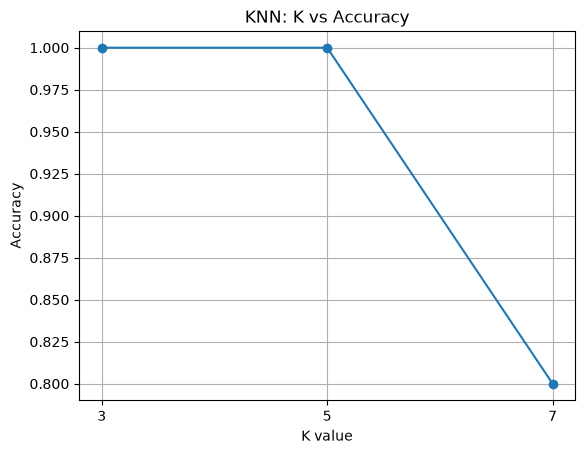

In [23]:
import matplotlib.pyplot as plt

plt.plot(k_values, accuracy_values, marker="o")

plt.xlabel("K value")
plt.ylabel("Accuracy")
plt.title("KNN: K vs Accuracy")
plt.xticks(k_values)
plt.grid(True)
plt.show()